# 3d (OSM variant) — Baseline Accessibility Analysis: Health Facilities, Costa Rica

## Purpose
Compute nearest-health-facility (hospital and clinic) travel times for the Costa Rican population and produce access-time figures, using **OpenStreetMap** as the facility source.

This is the OSM variant, kept for comparison. The main notebook `3d_Baseline_Accesibility_Analysis-hospital_CR.ipynb` now uses the official hospital register (`input_files/salud/hospitales_cr.shp`, 27 hospitals) and owns the canonical output paths; everything below is written to an `osm` figure folder, parquet folder and geodatabase so the two runs never overwrite each other.

## Inputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/network/main_network_directed.gpkg` | Directed, AADT-attributed main road network produced in 1b (EPSG:8908, `fft` in hours) |
| `input_files/cri_pd_2020_1km_UNadj_ASCII_XYZ.csv` | WorldPop 2020 UN-adjusted 1 km population **density** grid (WGS84, people per km²) |
| `input_files/costa-rica-260713.osm.pbf` | OSM extract — health facilities (`amenity=hospital` / `amenity=clinic`) |

## Outputs
| File | Description |
|------|-------------|
| `figures/osm/baseline_accessibility_hospitals.png` | Cumulative accessibility curve (population share vs. travel time) |
| `figures/osm/hospital_access.png` | Map of nearest-facility access times per 1 km population cell |
| `figures/osm/hospital_access_chart.png` | Population distribution chart by access-time band |
| `intermediate_results/parquet/local_accessibility/osm/hospital_accessibility_results.parquet` | Grid-cell access-time results (EPSG:8908) |
| `intermediate_results/parquet/local_accessibility/osm/hospitals.parquet` | Hospital/clinic sink points (EPSG:8908) |
| `intermediate_results/database/local_accessibility/local_accessibility_osm.gdb` | GDB layers: `hospital_accessibility_results`, `hospitals` |

## Key Processing Steps
1. **Extract facilities** — hospitals and clinics from the OSM `points` and `multipolygons` layers
2. **Load network** — read the directed main network from 1b and build an igraph graph (`fft` edge weights)
3. **Population grid** — convert WorldPop density to people per cell, snap each cell to the nearest network node
4. **Snap facilities** — nearest network node per hospital/clinic in the metric CRS
5. **Nearest-facility computation** — shortest-path travel time to the closest facility for every cell
6. **Save results** — write Parquet and ArcGIS File Geodatabase layers in EPSG:8908
7. **Plot curve, map and chart** — cumulative access curve, spatial access-time map, population by access band

## Caveats
- Travel times are network times on the **main network only** (1b scope): population cells and facilities snap to the nearest network node, so the first/last mile on local streets is not counted.
- OSM `amenity=hospital`/`clinic` tagging in Costa Rica mixes CCSS hospitals, clínicas/EBAIS and private specialty clinics; the sink list is only as good as the tagging.
- Because clinics/EBAIS are counted as sinks here, these access times are much shorter than the hospital-only register run and the two are not directly comparable.
- The cell outputs stored in this notebook are from the previous run, when it still wrote to the canonical paths; rerun it to regenerate them under `osm/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

BASE_DIR = Path.cwd().parent  # notebook lives in /notebooks
sys.path.append(str(BASE_DIR))

from utils.accessibility_functions import (
    create_graph_for_spatial_matching,
    map_settlements_to_nodes_in_road_network,
    nearest_network_nodes,
    get_distance_to_nearest_facility,
    save_accessibility_results,
    plot_access_curve,
    plot_access_time_map,
)

In [ ]:
# All paths are hard-coded here (no NetworkConfig) so they can be swapped one by one.
data_path = BASE_DIR / "input_files"
intermediate_path = BASE_DIR / "intermediate_results"

# Inputs
path_road_network = intermediate_path / "gpkg" / "network" / "main_network_directed.gpkg"  # from 1b
path_population = data_path / "cri_pd_2020_1km_UNadj_ASCII_XYZ.csv"  # WorldPop 1 km density grid
path_osm = data_path / "costa-rica-260713.osm.pbf"  # hospitals + clinics come from OSM

# Outputs — this OSM variant writes to its own "osm" figure folder, parquet folder
# and geodatabase. The filenames and GDB layer names inside them are fixed by
# utils.accessibility_functions (hospital_access.png, hospitals.parquet, ...), so
# separate directories are what keeps this run from overwriting the register-based
# run in 3d_Baseline_Accesibility_Analysis-hospital_CR.ipynb, which owns the
# canonical figures/ and local_accessibility/ outputs.
figure_dir = BASE_DIR / "figures" / "osm"
parquet_dir = intermediate_path / "parquet" / "local_accessibility" / "osm"
gdb_path = intermediate_path / "database" / "local_accessibility" / "local_accessibility_osm.gdb"
output_crs = "EPSG:8908"  # CR-SIRGAS / CRTM05 (metres) — same working CRS as notebooks 1b/2

for p in (path_road_network, path_population, path_osm):
    if not p.exists():
        raise FileNotFoundError(
            f"Missing input: {p}\n"
            "If this path lives on OneDrive, make sure the folder is downloaded locally "
            "('Always keep on this device') — cloud placeholders cannot be opened."
        )

In [3]:
import re

import geopandas as gpd
import pandas as pd

# OSM health facilities — extracted from the Costa Rica OSM extract.
# Facilities live in the "points" layer (single OSM nodes) and the
# "multipolygons" layer (buildings/grounds), not in "lines".
# "clinic" captures the CCSS clínicas / EBAIS alongside the hospitals,
# mirroring the hospitals-plus-health-centres scope of the Serbia analysis.
amenity_types = ["hospital", "clinic"]

def _extract_value(text, key):
    """
    Parse the value of a specific key from a semi-structured OSM tag string.

    Args:
        text (str): Raw OSM `other_tags` string.
        key (str): Key to extract value for.

    Returns:
        str or None: Extracted value or None.
    """
    pattern = rf'"{key}"=>"([^"]+)"'
    try:
        match = re.search(pattern, text)
        if match:
            return match.group(1)
        return None
    except Exception:
        return None

# Facilities mapped as single OSM nodes — `amenity` sits inside `other_tags`
points = gpd.read_file(path_osm, layer="points")
points["amenity"] = points["other_tags"].apply(lambda x: _extract_value(x, "amenity"))
hospital_points = points[points["amenity"].isin(amenity_types)]
hospital_points = hospital_points[["osm_id", "name", "amenity", "geometry"]]

# Facilities mapped as building/grounds polygons — `amenity` is a real column here
polygons = gpd.read_file(path_osm, layer="multipolygons")
hospital_polygons = polygons[polygons["amenity"].isin(amenity_types)].copy()
hospital_polygons["osm_id"] = hospital_polygons["osm_id"].fillna(
    hospital_polygons["osm_way_id"]
)
hospital_polygons["geometry"] = hospital_polygons.representative_point()
hospital_polygons = hospital_polygons[["osm_id", "name", "amenity", "geometry"]]

# Combine both geometry types into a single point layer (EPSG:4326)
hospitals = gpd.GeoDataFrame(
    pd.concat([hospital_points, hospital_polygons], ignore_index=True),
    geometry="geometry",
    crs="EPSG:4326",
)

# Longitude/Latitude columns to match the sink layout used by the Serbia inputs
hospitals["Longitude"] = hospitals.geometry.x
hospitals["Latitude"] = hospitals.geometry.y

print(
    f"{len(hospitals)} health facilities "
    f"({len(hospital_points)} points, {len(hospital_polygons)} polygons)"
)
print(hospitals["amenity"].value_counts().to_string())
hospitals.head()

1242 health facilities (506 points, 736 polygons)
amenity
clinic      1125
hospital     117


,osm_id,name,amenity,geometry,Longitude,Latitude
0,663378453,Ebais Concepción Norte,clinic,POINT (-83.99547 9.9218),-83.995468,9.921798
1,663378469,Ebais Villas de Ayarco,clinic,POINT (-84.01153 9.9022),-84.011526,9.902200
2,1136529989,EBAIS de Guadalupe,hospital,POINT (-83.93399 9.86303),-83.933986,9.863033
3,1224521127,Ebais San Antonio,clinic,POINT (-84.0555 9.89904),-84.055496,9.899044
4,1241642373,Ebais Puerto Carrillo,clinic,POINT (-85.4799 9.86479),-85.479896,9.864792


In [4]:
# Calibri is not installed on every machine (e.g. macOS); fall back quietly.
import matplotlib.font_manager as fm

if any(f.name == "Calibri" for f in fm.fontManager.ttflist):
    plt.rcParams["font.family"] = "Calibri"

In [5]:
# Build graph + nodes, snap population grid, snap facilities, compute nearest access time
base_network = gpd.read_file(path_road_network, layer="main_network_directed")
assert base_network.crs is not None and base_network.crs.to_epsg() == 8908, (
    f"Expected EPSG:8908, found {base_network.crs}"
)
missing = {"from_id", "to_id", "id", "fft"} - set(base_network.columns)
assert not missing, f"Network is missing required columns: {missing}"

nodes, graph = create_graph_for_spatial_matching(base_network)

# WorldPop 1 km grid: Z is population DENSITY (people per km²), so convert to
# people per cell with the latitude-dependent 30-arc-second cell area.
df_worldpop = pd.read_csv(path_population).rename(columns={"Z": "density"})
df_worldpop = df_worldpop[df_worldpop["density"] > 0].reset_index(drop=True)
cell_deg = 1 / 120  # 30 arc-seconds
cell_area_km2 = (111.320 * np.cos(np.radians(df_worldpop["Y"])) * cell_deg) * (
    110.574 * cell_deg
)
df_worldpop["population"] = df_worldpop["density"] * cell_area_km2
df_worldpop = gpd.GeoDataFrame(
    df_worldpop,
    geometry=gpd.points_from_xy(df_worldpop["X"], df_worldpop["Y"]),
    crs="EPSG:4326",
).to_crs(base_network.crs)
print(
    f"Population cells: {len(df_worldpop):,} | "
    f"total population: {df_worldpop['population'].sum():,.0f}"
)

df_worldpop = map_settlements_to_nodes_in_road_network(df_worldpop, nodes)

# Snap the OSM facilities (EPSG:4326) to the network in the metric CRS
sink_hospitals = hospitals.to_crs(base_network.crs)
nearest_network_nodes(sink_hospitals, nodes)

# Nearest facility for each population cell (slow step)
df_worldpop = get_distance_to_nearest_facility(
    df_worldpop, sink_hospitals, graph, id_col="osm_id"
)

# The closest_sink_* columns come back as object dtype; make them file-format safe
df_worldpop["closest_sink_total_fft"] = pd.to_numeric(
    df_worldpop["closest_sink_total_fft"], errors="coerce"
)
df_worldpop["closest_sink_vertex_id"] = pd.to_numeric(
    df_worldpop["closest_sink_vertex_id"], errors="coerce"
)
df_worldpop["closest_sink_osm_id"] = df_worldpop["closest_sink_osm_id"].astype(str)

  0%|          | 0/9764 [00:00<?, ?it/s]

 16%|█▌        | 1560/9764 [00:00<00:00, 15593.14it/s]

 32%|███▏      | 3169/9764 [00:00<00:00, 15856.84it/s]

 49%|████▊     | 4755/9764 [00:00<00:00, 15615.31it/s]

 66%|██████▌   | 6422/9764 [00:00<00:00, 16024.47it/s]

...

100%|██████████| 62053/62053 [00:13<00:00, 4688.55it/s]

  0%|          | 0/1242 [00:00<?, ?it/s]

 40%|███▉      | 494/1242 [00:00<00:00, 4932.27it/s]

 81%|████████  | 1001/1242 [00:00<00:00, 5008.94it/s]

100%|██████████| 1242/1242 [00:00<00:00, 4962.52it/s]

In [6]:
# Save results (Parquet + ArcGIS File Geodatabase, in the chosen output CRS)
save_accessibility_results(
    df_worldpop, sink_hospitals, "hospitals", parquet_dir, gdb_path, output_crs
)

Saved hospital_accessibility_results -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/parquet/local_accessibility/hospital_accessibility_results.parquet
Saved hospital_accessibility_results -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/database/local_accessibility/local_accessibility.gdb (layer 'hospital_accessibility_results')
Saved hospitals -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/parquet/local_accessibility/hospitals.parquet
Saved hospitals -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/database/local_accessibility/local_accessibility.gdb (layer 'hospitals')


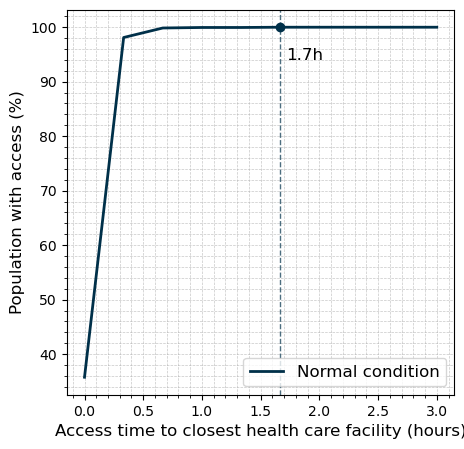

In [7]:
plot_access_curve(df_worldpop, "hospitals", figure_dir)

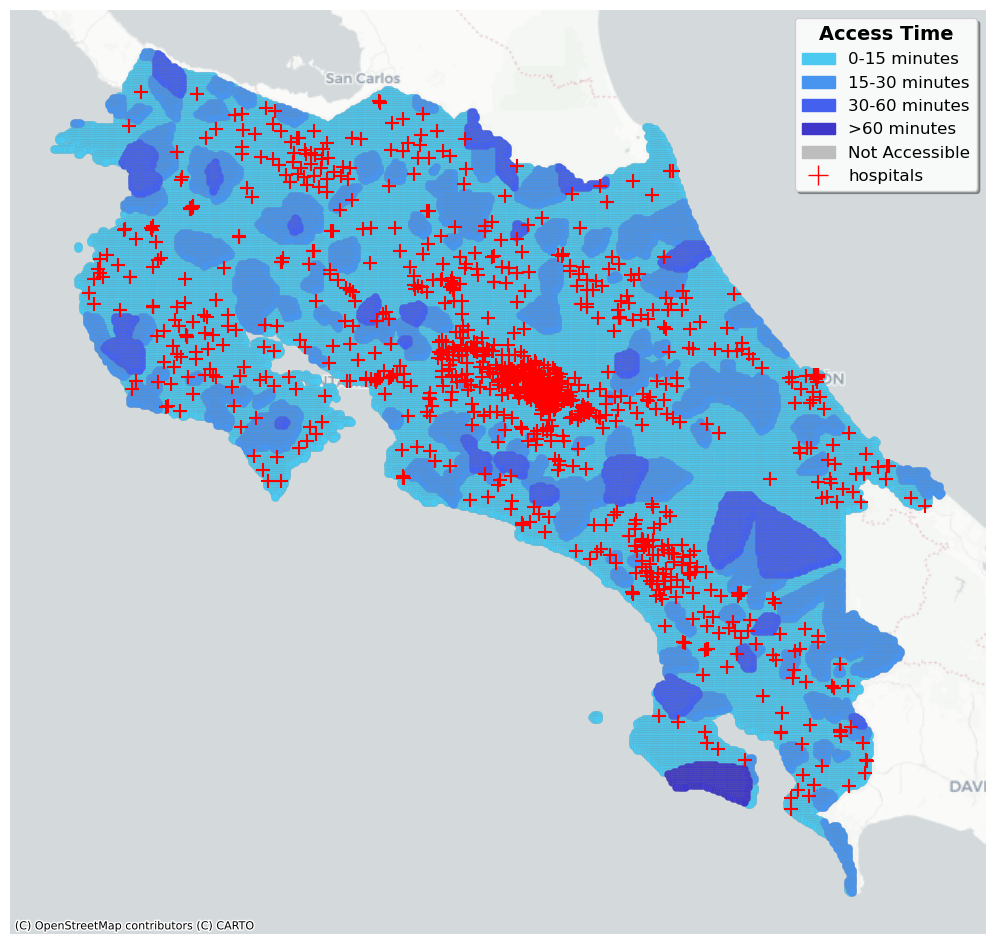

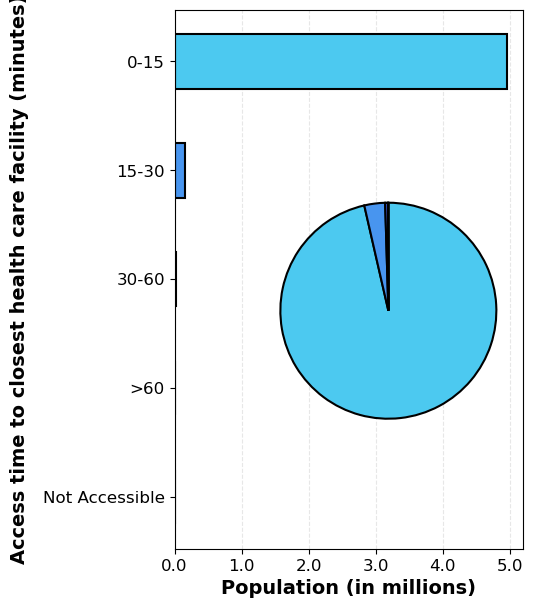

In [8]:
def plot_accessibility_chart_cr(df_worldpop_plot, figure_dir, show=True):
    """
    Costa Rica variant of utils' plot_accessibility_chart.

    The generic chart reindexes on hour-based categories ("60-90", ">120", ...)
    that plot_access_time_map does not produce, silently dropping the ">60" and
    "Not Accessible" population. This variant uses the exact categories and
    colours of the map so the two figures agree.
    """
    category_order = ["0-15", "15-30", "30-60", ">60", "Not Accessible"]
    category_colors = ["#4cc9f0", "#4895ef", "#4361ee", "#3f37c9", "#bdbdbd"]
    color_dict = dict(zip(category_order, category_colors))

    pop_by_category = (
        df_worldpop_plot.groupby("category")["population"].sum() / 1e6
    ).reindex(category_order, fill_value=0)
    pop_by_category_reversed = pop_by_category[::-1]

    fig, ax = plt.subplots(figsize=(4.5, 7))
    ax.barh(
        range(len(pop_by_category_reversed)),
        pop_by_category_reversed.values,
        height=0.5,
        color=[color_dict[cat] for cat in pop_by_category_reversed.index],
        edgecolor="black",
        linewidth=1.5,
    )
    ax.set_ylabel(
        "Access time to closest health care facility (minutes)",
        fontsize=14,
        fontweight="bold",
        labelpad=10,
    )
    ax.set_xlabel("Population (in millions)", fontsize=14, fontweight="bold")
    ax.set_yticks(range(len(pop_by_category_reversed)))
    ax.set_yticklabels(pop_by_category_reversed.index, fontsize=12)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:.1f}"))
    ax.tick_params(axis="x", labelsize=12)
    ax.grid(axis="x", alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)

    # Inset pie chart, same order and colours as the bars
    ax_inset = fig.add_axes([0.3, 0.15, 0.6, 0.6])
    ax_inset.pie(
        pop_by_category.values,
        colors=[color_dict[cat] for cat in pop_by_category.index],
        startangle=90,
        counterclock=False,
        wedgeprops={"edgecolor": "black", "linewidth": 1.5},
    )

    figure_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(figure_dir / "hospital_access_chart.png", dpi=200, bbox_inches="tight")
    if show:
        plt.show()


# Access-time map + population distribution chart
df_worldpop_plot = plot_access_time_map(
    df_worldpop, sink_hospitals, "hospitals", figure_dir
)
plot_accessibility_chart_cr(df_worldpop_plot, figure_dir)